In [27]:
import tensorflow as tf
import matplotlib.pyplot as plt 


In [28]:
import os 
print("Current working Directory:",os.getcwd())

Current working Directory: c:\Users\RAKSHITHA.V\OneDrive\Documents\AICW\python basics\Plant_diseases


In [29]:
current_directory =os.getcwd()
test_path = os.path.join(current_directory, "data","Testing")
train_path = os.path.join(current_directory,"data","Training")
valid_path= os.path.join(current_directory,"data","Validation")

In [30]:
training_set = tf.keras.utils.image_dataset_from_directory(
    train_path,
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128,128),
    shuffle=True,
    interpolation="bilinear",
    
    
)

Found 3251 files belonging to 3 classes.


In [31]:
Validation_set = tf.keras.utils.image_dataset_from_directory(
    valid_path,
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    interpolation="bilinear",
)

Found 416 files belonging to 3 classes.


In [32]:
Testing_set = tf.keras.utils.image_dataset_from_directory(
    test_path,
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    interpolation="bilinear",
)

Found 405 files belonging to 3 classes.


In [33]:
cnn = tf.keras.models.Sequential()

cnn.add(tf.keras.layers.Conv2D(filters=32,kernel_size=3,padding='same',activation='relu',input_shape=[128,128,3]))
cnn.add(tf.keras.layers.Conv2D(filters=32,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=256,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=256,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=512,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=512,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Dropout(0.25))

cnn.add(tf.keras.layers.Flatten())
cnn.add(tf.keras.layers.Dense(units=1500,activation='relu'))
cnn.add(tf.keras.layers.Dropout(0.4))

cnn.add(tf.keras.layers.Dense(units=3,activation='softmax'))

c:\Users\RAKSHITHA.V\OneDrive\Documents\AICW\python basics\Plant_diseases\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [34]:
cnn.compile(optimizer=tf.keras.optimizers.Adam(
    learning_rate=0.001),loss='categorical_crossentropy',metrics=['accuracy'])

In [35]:
cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 126, 126, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 63, 63, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 61, 61, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 30, 30, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 14, 14, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 6, 6, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1500)           │     3,073,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │         4,503 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,790,227 (29.72 MB)

 Trainable params: 7,790,227 (29.72 MB)

 Non-trainable params: 0 (0.00 B)

In [37]:
training_history = cnn.fit(x=training_set,validation_data=Validation_set,epochs=10)

Epoch 1/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 63s 616ms/step - accuracy: 0.6032 - loss: 0.8465 - val_accuracy: 0.5745 - val_loss: 0.8655
Epoch 2/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 62s 611ms/step - accuracy: 0.5912 - loss: 0.9339 - val_accuracy: 0.6466 - val_loss: 0.8228
Epoch 3/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 63s 616ms/step - accuracy: 0.6373 - loss: 0.8365 - val_accuracy: 0.6442 - val_loss: 0.8019
Epoch 4/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 70s 683ms/step - accuracy: 0.6678 - loss: 0.7701 - val_accuracy: 0.7572 - val_loss: 0.6861
Epoch 5/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 105s 1s/step - accuracy: 0.6736 - loss: 0.7698 - val_accuracy: 0.7476 - val_loss: 0.6576
Epoch 6/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 105s 1s/step - accuracy: 0.6358 - loss: 0.8453 - val_accuracy: 0.6442 - val_loss: 0.8340
Epoch 7/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 205s 2s/step - accuracy: 0.6666 - loss: 0.7775 - val_accuracy: 0.7692 - val_loss: 0.5624
Epoch 8/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 62s 606ms/step - accuracy: 0.8013 - loss: 0.4994 

In [43]:
val_los,val_acc=cnn.evaluate(Validation_set)
print("Validation Loss:",val_los)

13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 198ms/step - accuracy: 0.9038 - loss: 0.2362
Validation Loss: 0.23617979884147644


In [44]:
cnn.save('train_plant_leaf_disease_model.keras')

In [45]:
training_history.history

{'accuracy': [0.6031990051269531,
  0.5912027359008789,
  0.6373423337936401,
  0.6677945256233215,
  0.6736388802528381,
  0.6358043551445007,
  0.6665641069412231,
  0.8012918829917908,
  0.841894805431366,
  0.8920332193374634],
 'loss': [0.8465179800987244,
  0.9338706135749817,
  0.83650141954422,
  0.7701048254966736,
  0.7698332667350769,
  0.8452656865119934,
  0.7774831056594849,
  0.4994148910045624,
  0.40871211886405945,
  0.2890051305294037],
 'val_accuracy': [0.5745192170143127,
  0.6466346383094788,
  0.6442307829856873,
  0.7572115659713745,
  0.7475961446762085,
  0.6442307829856873,
  0.7692307829856873,
  0.8509615659713745,
  0.8846153616905212,
  0.9038461446762085],
 'val_loss': [0.8655150532722473,
  0.8228051066398621,
  0.8018994927406311,
  0.6860822439193726,
  0.6576109528541565,
  0.8339911103248596,
  0.5624358057975769,
  0.42444291710853577,
  0.3107861876487732,
  0.23617979884147644]}

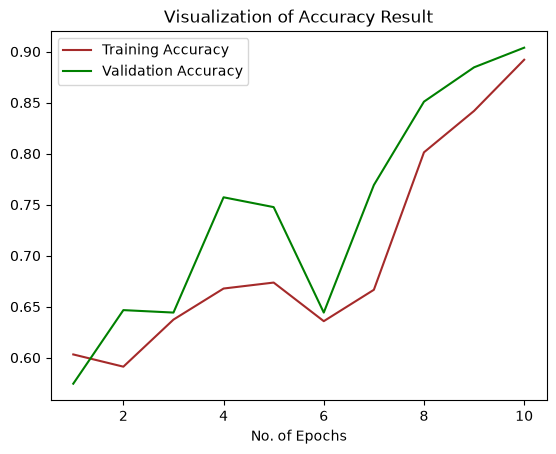

In [46]:
epochs = [i for i in range(1,11)]
plt.plot(epochs,training_history.history['accuracy'],color='brown',label='Training Accuracy')
plt.plot(epochs,training_history.history['val_accuracy'],color='green',label='Validation Accuracy')
plt.xlabel('No. of Epochs')
plt.title('Visualization of Accuracy Result')
plt.legend()
plt.show()